# 2107541 Machine Learning for Environmental Applications
## Lecture 8 : Unsupervised Learning - Clustering
### Done By : 6730084521 Chatrphol Ovanonchai

## Step 1: Import the Dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("bangkok_solid_waste_clustering.csv")
df.head()

,Year,District,Population_2025,Total_Waste_tonnes_year,Waste_per_capita_tonnes_person_year,Waste_per_capita_kg_person_day
0,2025,Nong Chok,187987,57433.91,0.306,0.84
1,2025,Sai Mai,212912,78514.33,0.369,1.01
2,2025,Khlong Sam Wa,215427,84237.69,0.391,1.07
3,2025,Don Mueang,165594,65284.14,0.394,1.08
4,2025,Nong Khaem,154690,61413.63,0.397,1.09


## Step 2: Explore the Dataset

In [2]:
df.shape

(50, 6)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Year                                 50 non-null     int64  
 1   District                             50 non-null     str    
 2   Population_2025                      50 non-null     int64  
 3   Total_Waste_tonnes_year              50 non-null     float64
 4   Waste_per_capita_tonnes_person_year  50 non-null     float64
 5   Waste_per_capita_kg_person_day       50 non-null     float64
dtypes: float64(3), int64(2), str(1)
memory usage: 3.0 KB


In [6]:
df.isnull().sum()

Year                                   0
District                               0
Population_2025                        0
Total_Waste_tonnes_year                0
Waste_per_capita_tonnes_person_year    0
Waste_per_capita_kg_person_day         0
dtype: int64

In [7]:
df.describe()

,Year,Population_2025,Total_Waste_tonnes_year,Waste_per_capita_tonnes_person_year,Waste_per_capita_kg_person_day
count,50.0,50.000000,50.000000,50.00000,50.00000
mean,2025.0,107573.540000,67389.252600,0.71662,1.96340
std,0.0,49823.242518,26107.218515,0.37707,1.03296
min,2025.0,18329.000000,16322.330000,0.30600,0.84000
25%,2025.0,73114.000000,49585.505000,0.49250,1.34500
50%,2025.0,97582.000000,59821.765000,0.60100,1.65000
75%,2025.0,139804.000000,85777.582500,0.80325,2.19750
max,2025.0,215427.000000,128935.840000,2.54900,6.98000


## Step 3: Visualize the original data

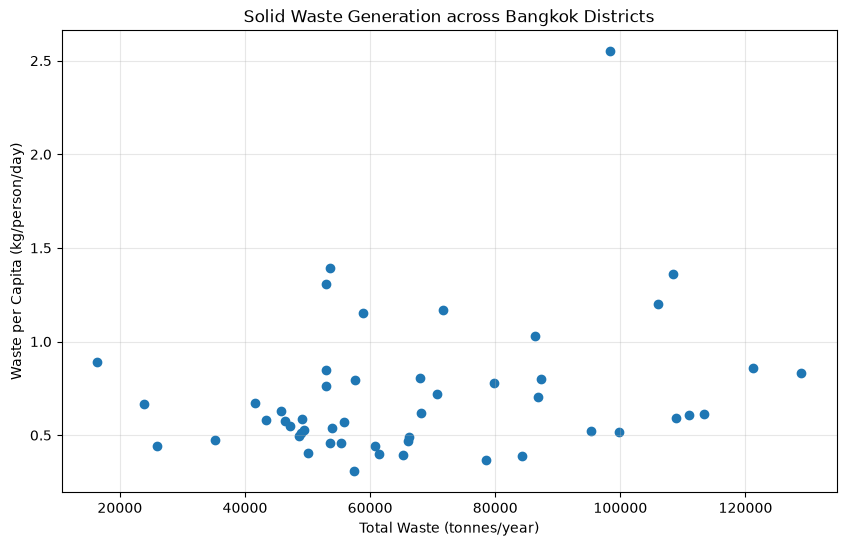

In [9]:
plt.figure(figsize=(10, 6))

## scatter between Total_Waste_tonnes_year and Waste_per_capita_tonnes_person_year
plt.scatter( 
            x = df["Total_Waste_tonnes_year"] , y = df["Waste_per_capita_tonnes_person_year"] )

## decorate graoh 
plt.xlabel("Total Waste (tonnes/year)")
plt.ylabel("Waste per Capita (kg/person/day)")
plt.title("Solid Waste Generation across Bangkok Districts")
plt.grid(True, alpha=0.3)
plt.show()

## Step 4: Select features and standardize them

In [10]:
from sklearn.preprocessing import StandardScaler

features = ["Total_Waste_tonnes_year","Waste_per_capita_tonnes_person_year"]
# copy features
X = df[features].copy()

# defin escaler
scaler = StandardScaler()

## fit then transform 
X_scaled = scaler.fit_transform(X)

print("Original data shape:", X.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (50, 2)
Scaled data shape: (50, 2)


## Step 5: K-means 

In [11]:
from sklearn.cluster import KMeans

## using kmeans
kmeans = KMeans(
 n_clusters=3,
 init="k-means++", ## start seperating centroid apart 
 n_init=10,
 random_state=42
)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print(df["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    12
1     8
2    30
Name: count, dtype: int64


## Step 6: Gaussian Mixture Model (GMM) 

In [ ]:
from sklearn.mixture import GaussianMixture
### gmm , probs of cluster 

## define guassian mixture 
gmm = GaussianMixture(
 n_components=3,
 random_state=42
)

## fit then predict 
## add to df
df["GMM_Cluster"] = gmm.fit_predict(X_scaled)
print(df["GMM_Cluster"].value_counts().sort_index())

GMM_Cluster
0    20
1     3
2    27
Name: count, dtype: int64


## Step 7: DBSCAN 

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps = 0.7 , min_samples = 4) ## distance for finding neighbours 

## add to df
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)
print(df["DBSCAN_Cluster"].value_counts().sort_index())

"""
Interpret the labels as follows:
● -1: Noise points.
● 0, 1, etc.: Identified clusters
"""

DBSCAN_Cluster
-1     5
 0    41
 1     4
Name: count, dtype: int64


## Step 8: Agglomerative Clustering 

In [17]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(
 n_clusters=3,
 linkage="ward" ) ## using ward's method for grouping cluster

## fit_predict then add to df
df["Agglomerative_Cluster"] = agg.fit_predict(X_scaled)

## print result
print(
 df["Agglomerative_Cluster"]
 .value_counts()
 .sort_index() )

Agglomerative_Cluster
0     5
1    36
2     9
Name: count, dtype: int64


## Step 9: Plot the clusters from all four algorithms 

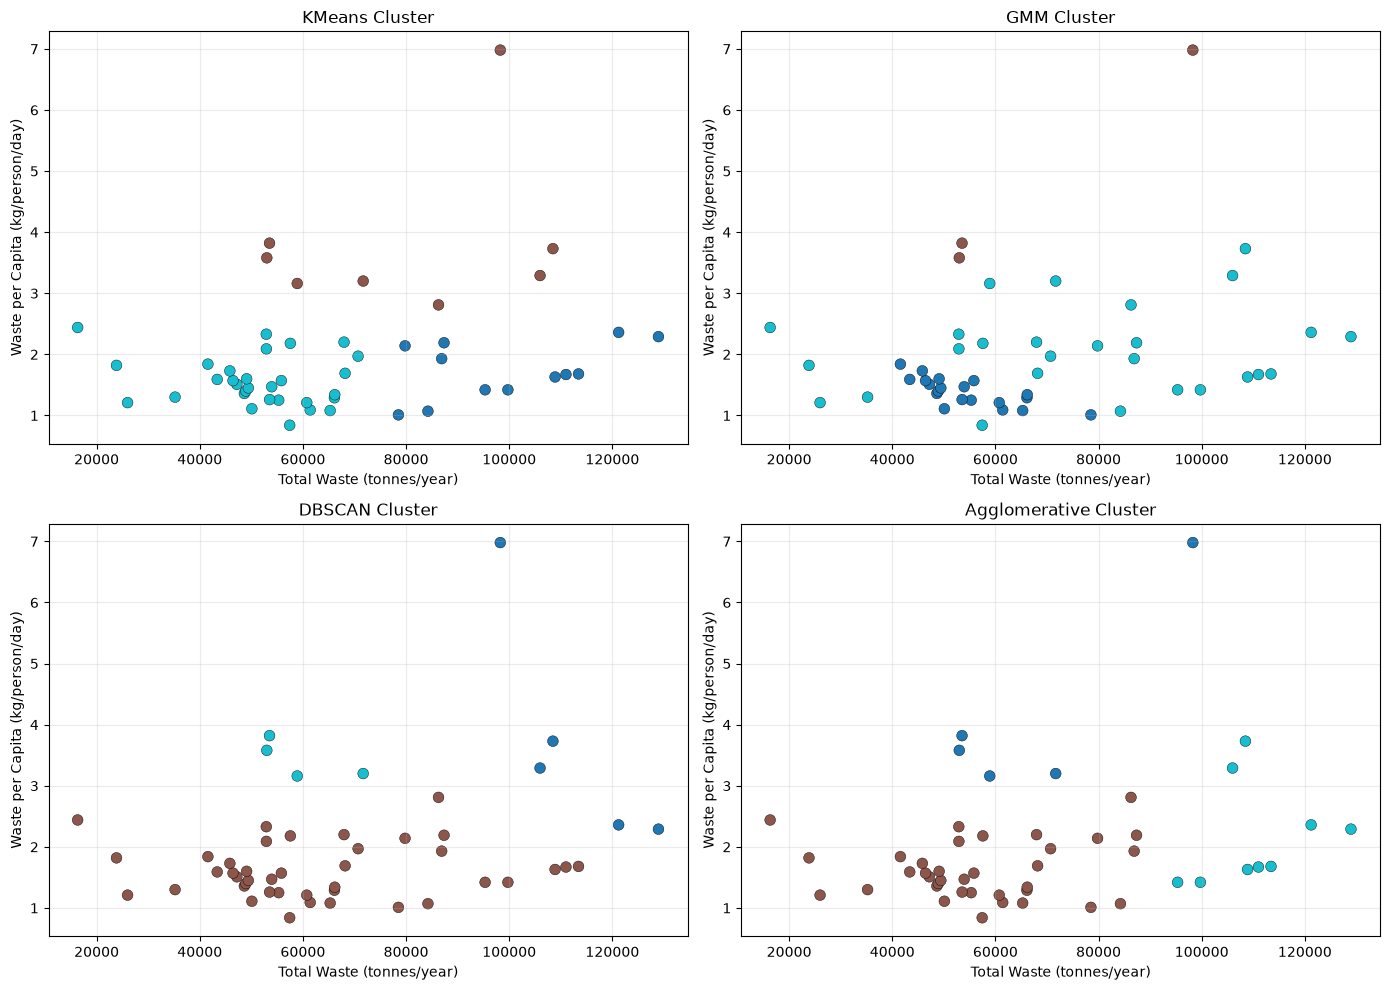

In [18]:
cluster_columns = [
 "KMeans_Cluster",
 "GMM_Cluster",
 "DBSCAN_Cluster",
 "Agglomerative_Cluster"
]

## subplot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flatten(), cluster_columns):
    scatter = ax.scatter(
    df["Total_Waste_tonnes_year"],
    df["Waste_per_capita_kg_person_day"],
    c=df[col],
    cmap="tab10",
    s=60,
    edgecolor="black",
    linewidth=0.3
    )
    
    ## decorate plot
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Total Waste (tonnes/year)")
    ax.set_ylabel("Waste per Capita (kg/person/day)")
    ax.grid(True, alpha=0.25)
    
plt.tight_layout()
plt.show()

## Step 10: Summarize each cluster 

In [20]:
for each_cluster_techniques in cluster_columns:
    print(f"\n--- {each_cluster_techniques} ---")
    
    ## groupby each clustering techniques 
    ## then get data for each perspective 
    summary = df.groupby(each_cluster_techniques).agg(
    
        # perspective 1 : district count
        Number_of_Districts=("District", "count"),
        
        # perspective 2 : mean total waster
        Mean_Total_Waste=("Total_Waste_tonnes_year", "mean"),
        
        # perspective 3 : mean waste per capita
        Mean_Waste_per_Capita=("Waste_per_capita_kg_person_day", "mean")

    ).round(2)
    
    # display summary 
    display(summary)


--- KMeans_Cluster ---


,Number_of_Districts,Mean_Total_Waste,Mean_Waste_per_Capita
KMeans_Cluster,,,
0,12,99613.86,1.73
1,8,79515.08,3.82
2,30,51265.85,1.56



--- GMM_Cluster ---


,Number_of_Districts,Mean_Total_Waste,Mean_Waste_per_Capita
GMM_Cluster,,,
0,20,54372.07,1.39
1,3,68264.44,4.79
2,27,76934.37,2.08



--- DBSCAN_Cluster ---


,Number_of_Districts,Mean_Total_Waste,Mean_Waste_per_Capita
DBSCAN_Cluster,,,
-1,5,112574.74,3.73
0,41,62670.24,1.60
1,4,59277.29,3.44



--- Agglomerative_Cluster ---


,Number_of_Districts,Mean_Total_Waste,Mean_Waste_per_Capita
Agglomerative_Cluster,,,
0,5,67075.94,4.15
1,36,56696.86,1.61
2,9,110332.88,2.17


## Step 11: Compare cluster quality using Silhouette Score 

In [24]:
from sklearn.metrics import silhouette_score
results = {}
for each_cluster_techniques in cluster_columns:
    
    ## convert data labels to numpy 
    labels = df[each_cluster_techniques].to_numpy()
    
    # DBSCAN noise points have label -1.
    # Exclude noise when evaluating DBSCAN's identified clusters.
    
    ## check if it's dbscan , mask -1 out     
    if each_cluster_techniques == "DBSCAN_Cluster":
        mask = labels != -1
        X_eval = X_scaled[mask]
        labels_eval = labels[mask]
        
    else:
        X_eval = X_scaled
        labels_eval = labels
    
    ## define n_clusters
    n_clusters = len(np.unique(labels_eval)) ## labels_eval = array of cluster_number
 
    ## n_clusters is validate
    if 2 <= n_clusters < len(labels_eval):
        score = silhouette_score(X_eval, labels_eval)
        results[each_cluster_techniques] = score
 
    else:
        results[each_cluster_techniques] = np.nan
    
    ## get dataframe out 
    results_df = pd.DataFrame(
            results.items(),
            columns=["Algorithm", "Silhouette_Score"]
    ).sort_values("Silhouette_Score", ascending=False)
    
display(results_df)

,Algorithm,Silhouette_Score
3,Agglomerative_Cluster,0.481625
0,KMeans_Cluster,0.476802
2,DBSCAN_Cluster,0.416875
1,GMM_Cluster,0.228699


## Step 12: Discussion and interpretation
1. Select one clustering algorithm based on your opinion

2. List all Bangkok districts belonging to each cluster according to
your selected clustering algorithm.

3. Recommend waste management strategies for each cluster.
(make comments in Colab)

> Hint: Consider strategies such as waste reduction, source separation, recycling, food waste management,
public awareness campaigns, and improvements in waste collection and transportation. 

/var/folders/t7/hn7xqdgs28vbkzlq0tg_5m480000gn/T/ipykernel_39251/410920485.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


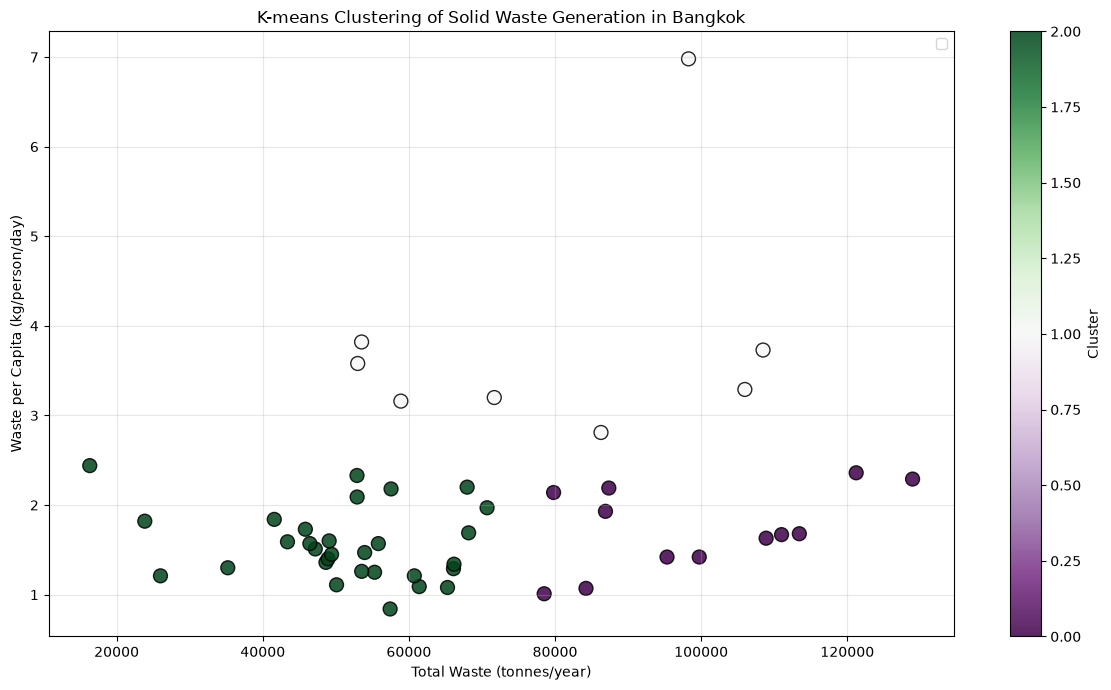

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot clustering results using the original feature values
plt.figure(figsize=(12, 7))
scatter = plt.scatter(
    df["Total_Waste_tonnes_year"],
    df["Waste_per_capita_kg_person_day"],
    
    ## KMeans_Cluster/GMM_Cluster/DBSCAN_Cluster/Agglomerative_Cluster
    
    c=df["KMeans_Cluster"], ## change clustering techniques here
    cmap="PRGn",
    s=100,
    edgecolor="black",
 alpha=0.85 )

## decorate graph 
plt.xlabel("Total Waste (tonnes/year)")
plt.ylabel("Waste per Capita (kg/person/day)")
plt.title("K-means Clustering of Solid Waste Generation in Bangkok")
plt.colorbar(scatter, label="Cluster")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [34]:
# Group districts by their K-means cluster
for cluster_id in sorted(df["KMeans_Cluster"].unique()):
    districts = df.loc[
    df["KMeans_Cluster"] == cluster_id,
    "District"
    ].sort_values().tolist()
    
    print(f"\nCluster {cluster_id}")
    print(f"Number of districts: {len(districts)}")
    
    for district in districts:
        print(f"- {district}")


Cluster 0
Number of districts: 12
- Bang Kapi
- Bang Khae
- Bang Khen
- Bang Khun Thian
- Chatuchak
- Din Daeng
- Khlong Sam Wa
- Lat Krabang
- Prawet
- Sai Mai
- Suan Luang
- Wang Thonglang

Cluster 1
Number of districts: 8
- Bang Rak
- Bangkok Noi
- Huai Khwang
- Khlong Toei
- Pathum Wan
- Phra Nakhon
- Ratchathewi
- Watthana

Cluster 2
Number of districts: 30
- Bang Bon
- Bang Kho Laem
- Bang Na
- Bang Phlat
- Bang Sue
- Bangkok Yai
- Bueng Kum
- Chom Thong
- Don Mueang
- Dusit
- Khan Na Yao
- Khlong San
- Lak Si
- Lat Phrao
- Min Buri
- Nong Chok
- Nong Khaem
- Phasi Charoen
- Phaya Thai
- Phra Khanong
- Pom Prap Sattru Phai
- Rat Burana
- Samphanthawong
- Saphan Sung
- Sathon
- Taling Chan
- Thawi Watthana
- Thon Buri
- Thung Khru
- Yan Nawa


In [ ]:
## visualizing districts in each cluster 

## summary table of each cluster (selected algorithm : K-means)
cluster_table = df.groupby("KMeans_Cluster").agg(
    Number_of_Districts   = ("District" , "count") ,
    Mean_Total_Waste      = ("Total_Waste_tonnes_year" , "mean") ,
    Mean_Waste_per_Capita = ("Waste_per_capita_kg_person_day" , "mean") ,
    Mean_Population       = ("Population_2025" , "mean") ,
    Districts             = ("District" , ", ".join) ,    # join all district names in each cluster
).round(2)

## show full district names (pandas cuts long text by default)
pd.set_option("display.max_colwidth" , None)

display(cluster_table)

,Number_of_Districts,Mean_Total_Waste,Mean_Waste_per_Capita,Mean_Population,Districts
KMeans_Cluster,,,,,
0,12,99613.86,1.73,165382.33,"Sai Mai, Khlong Sam Wa, Bang Khae, Bang Khen, Prawet, Lat Krabang, Bang Khun Thian, Suan Luang, Wang Thonglang, Din Daeng, Chatuchak, Bang Kapi"
1,8,79515.08,3.82,60257.88,"Huai Khwang, Bangkok Noi, Ratchathewi, Khlong Toei, Bang Rak, Watthana, Phra Nakhon, Pathum Wan"
2,30,51265.85,1.56,97067.53,"Nong Chok, Don Mueang, Nong Khaem, Thung Khru, Chom Thong, Bangkok Yai, Phasi Charoen, Bang Sue, Min Buri, Rat Burana, Bueng Kum, Saphan Sung, Thon Buri, Khan Na Yao, Taling Chan, Bang Phlat, Lak Si, Thawi Watthana, Bang Kho Laem, Phra Khanong, Lat Phrao, Dusit, Pom Prap Sattru Phai, Khlong San, Bang Bon, Sathon, Yan Nawa, Bang Na, Phaya Thai, Samphanthawong"


## Step 12 : Discussion and Interpretation (AI-Assisted)

### 1. Selected algorithm : K-means
- Its Silhouette Score (0.477) is almost the same as the highest one , Agglomerative (0.482)
- It gives more balanced groups (12 / 8 / 30) than Agglomerative (5 / 36 / 9) , which makes it easier to plan a different strategy for each group
- DBSCAN puts 41 districts in one cluster , and GMM has the lowest score (0.229)

### 2. Districts in each cluster

| Cluster | Districts | Mean total waste (tonnes/year) | Mean waste per capita (kg/person/day) | Mean population | Name |
|---|---|---|---|---|---|
| 0 | 12 | 99,614 | 1.73 | 165,382 | High total waste , large population |
| 1 | 8 | 79,515 | 3.82 | 60,258 | High waste per person , small population |
| 2 | 30 | 51,266 | 1.56 | 97,068 | Low total waste , low waste per person |

**Cluster 0 :** Sai Mai , Khlong Sam Wa , Bang Khae , Bang Khen , Prawet , Lat Krabang , Bang Khun Thian , Suan Luang , Wang Thonglang , Din Daeng , Chatuchak , Bang Kapi

**Cluster 1 :** Huai Khwang , Bangkok Noi , Ratchathewi , Khlong Toei , Bang Rak , Watthana , Phra Nakhon , Pathum Wan

**Cluster 2 :** Nong Chok , Don Mueang , Nong Khaem , Thung Khru , Chom Thong , Bangkok Yai , Phasi Charoen , Bang Sue , Min Buri , Rat Burana , Bueng Kum , Saphan Sung , Thon Buri , Khan Na Yao , Taling Chan , Bang Phlat , Lak Si , Thawi Watthana , Bang Kho Laem , Phra Khanong , Lat Phrao , Dusit , Pom Prap Sattru Phai , Khlong San , Bang Bon , Sathon , Yan Nawa , Bang Na , Phaya Thai , Samphanthawong

### 3. Recommended waste management strategies

**Cluster 0 : the problem is the total amount of waste**
> Waste per person is normal , but the large population creates a lot of waste in total
- Improve collection and transportation (more frequent rounds , better routes , transfer stations)
- Promote source separation at home , so less mixed waste has to be transported
- Set up community recycling points in housing areas

**Cluster 1 : the problem is high waste per person**
> Each resident accounts for more than twice the waste of the other clusters , even with the smallest population. This may be because these districts include many businesses and tourist areas , so waste also comes from visitors and workers who are not counted as residents (the dataset cannot confirm this)
- Reduce waste at the source , especially from businesses (less single-use packaging)
- Manage food waste from restaurants , hotels and markets (separate collection , composting)
- Run awareness campaigns aimed at businesses and visitors , not only residents

**Cluster 2 : the lowest waste levels , maintain and improve**
> This cluster has the lowest values for both total waste and waste per person , so no urgent action is needed
- Run public awareness campaigns to keep waste per person low as the city grows
- Expand recycling and source separation
- Support home composting of food waste where there is enough space

**Overall :** The clusters need different strategies : Cluster 0 needs better collection , Cluster 1 needs waste reduction at the source , and Cluster 2 needs its current low levels maintained
